# DSAA 5020 Final Project — Topic 8 (Standalone Colab Edition)
## Can Transfer Learning Outperform Training from Scratch with Limited Labeled Data?

This notebook is **100% self-contained** (no manual Drive upload required). Make sure Runtime is set to **T4 GPU** and run all cells!

In [1]:
# 1. Unpack self-contained src/ modules & verify GPU
import base64, os, zipfile
from io import BytesIO
from pathlib import Path
import torch, torchvision

WORK_DIR = Path("/content/dsaa5020_topic8")
WORK_DIR.mkdir(parents=True, exist_ok=True)
os.chdir(WORK_DIR)

SRC_ZIP_B64 = (
    "..."
)
with zipfile.ZipFile(BytesIO(base64.b64decode(SRC_ZIP_B64))) as zf:
    zf.extractall(WORK_DIR)

print("Unpacked src files:", sorted(p.name for p in (WORK_DIR / "src").glob("*.py")))
print(f"PyTorch: {torch.__version__}, TorchVision: {torchvision.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
else:
    print("WARNING: No GPU detected! Switch Runtime -> Change runtime type -> T4 GPU.")


Unpacked src files: ['__init__.py', 'dataset.py', 'models.py', 'run_experiments.py', 'train.py', 'utils.py', 'visualize.py']
PyTorch: 2.14.1+cu130, TorchVision: 0.29.1+cu130
CUDA available: True
GPU: NVIDIA L4


In [2]:
# 2. Run Core + Extended + MobileNetV3-Small Cross-Backbone Experiments (~20-30 min on T4 GPU)
MODE = "full_with_mobilenet"
!python -m src.run_experiments \
    --mode {MODE} \
    --data_dir /content/data \
    --output_dir /content/dsaa5020_topic8/results \
    --seeds 42 123 2026 \
    --curve_seeds 42 \
    --num_workers 2


=== Step 1: Computing Oxford-IIIT Pet EDA Summary ===
100% 792M/792M [00:43<00:00, 18.1MB/s]
100% 19.2M/19.2M [00:01<00:00, 10.2MB/s]
Dataset: Oxford-IIIT Pet | Total=7349 imgs | Classes=37 (12 cats, 25 dogs)
Splits: train_100=2944, train_10=295, val=736, test=3669

=== Step 2: Running 44 Experiments (mode=full_with_mobilenet) ===

--- [1/44] resnet18 | scratch | 10% | seed=42 ---

>>> Running resnet18 | scratch | 10% data (295 imgs) | seed=42 | device=cuda
[DONE] resnet18/scratch_f010_s42 | BestEp=65/80 | ValAcc=15.08% | TestAcc=12.84% | TestF1=12.64% | TrainTime=142.4s (to best: 116.0s)

--- [2/44] resnet18 | frozen | 10% | seed=42 ---
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
100% 44.7M/44.7M [00:00<00:00, 239MB/s]

>>> Running resnet18 | frozen | 10% data (295 imgs) | seed=42 | device=cuda
[DONE] resnet18/frozen_f010_s42 | BestEp=7/19 | ValAcc=85.87% | TestAcc=83.21% | TestF1=82.89% | TrainTi

In [3]:
# 3. Generate all summary tables (CSV + Markdown) and 300 DPI figures (fig1 - fig8)
!python -m src.visualize --output_dir /content/dsaa5020_topic8/results --data_dir /content/data


Summary table written to /content/dsaa5020_topic8/results/tables/summary_table.md
Generated 8 figures in /content/dsaa5020_topic8/results/figures: fig1_eda_class_distribution.png, fig2_model_comparison_10pct.png, fig3_data_efficiency_curve.png, fig4_generalization_curves_and_gap.png, fig5_tsne_representations.png, fig6_efficiency_tradeoff.png, fig7_error_analysis.png, fig8_backbone_comparison.png


# Experiment Results Summary

| Backbone | Data % | Strategy | Seeds | Trainable Params | Test Accuracy | Test Macro-F1 | Train-Val Gap (Best) | Best Ep | Time to Best (s) | Total Time (s) |
| :--- | :---: | :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| mobilenet_v3_small | 10% | Scratch | 1 | 1.56M | 2.73% | 0.14% | -0.68% | 1.0 | 9.1s | 46.73s |
| mobilenet_v3_small | 10% | Frozen | 1 | 0.63M | 75.14% | 74.87% | +22.28% | 11.0 | 20.0s | 41.67s |
| mobilenet_v3_small | 10% | Partial FT | 1 | 1.27M | 66.61% | 66.09% | +26.22% | 24.0 | 42.2s | 63.15s |
| mobilenet_v3_small | 10% | Full FT | 1 | 1.56M | 65.44% | 64.59% | +27.45% | 23.0 | 41.7s | 63.22s |
| mobilenet_v3_small | 100% | Scratch | 1 | 1.56M | 41.24% | 40.75% | +48.74% | 59.0 | 969.8s | 1295.10s |
| mobilenet_v3_small | 100% | Frozen | 1 | 0.63M | 86.37% | 86.20% | +10.19% | 31.0 | 494.8s | 635.08s |
| mobilenet_v3_small | 100% | Partial FT | 1 | 1.27M | 82.94% | 82.74% | +10.05% | 16.0 | 250.0s | 436.44s |
| mobilenet_v3_small | 100% | Full FT | 1 | 1.56M | 84.27% | 84.09% | +9.61% | 27.0 | 421.4s | 607.53s |
| resnet18 | 5% | Scratch | 1 | 11.20M | 8.64% | 8.52% | +86.43% | 34.0 | 31.8s | 50.70s |
| resnet18 | 5% | Frozen | 1 | 19.0K | 81.55% | 81.47% | +17.53% | 23.0 | 21.4s | 32.60s |
| resnet18 | 5% | Partial FT | 1 | 8.41M | 69.94% | 69.76% | +29.21% | 12.0 | 11.3s | 22.56s |
| resnet18 | 5% | Full FT | 1 | 11.20M | 68.90% | 68.81% | +29.76% | 9.0 | 8.6s | 19.86s |
| resnet18 | 10% | Scratch | 3 | 11.20M | 14.09 ± 1.09% | 13.74 ± 1.01% | +82.50% | 73.0 | 126.8s | 139.01 ± 3.01s |
| resnet18 | 10% | Frozen | 3 | 19.0K | 83.65 ± 0.39% | 83.37 ± 0.45% | +12.68% | 18.7 | 31.8s | 51.03 ± 17.64s |
| resnet18 | 10% | Partial FT | 3 | 8.41M | 77.09 ± 0.73% | 76.65 ± 0.91% | +18.84% | 7.7 | 13.3s | 33.77 ± 2.96s |
| resnet18 | 10% | Full FT | 3 | 11.20M | 77.81 ± 0.50% | 77.36 ± 0.65% | +18.37% | 14.7 | 25.3s | 46.11 ± 10.87s |
| resnet18 | 25% | Scratch | 1 | 11.20M | 25.76% | 25.23% | +71.06% | 64.0 | 273.0s | 340.97s |
| resnet18 | 25% | Frozen | 1 | 19.0K | 87.68% | 87.42% | +9.51% | 15.0 | 64.3s | 114.58s |
| resnet18 | 25% | Partial FT | 1 | 8.41M | 85.04% | 84.74% | +13.59% | 11.0 | 47.3s | 97.88s |
| resnet18 | 25% | Full FT | 1 | 11.20M | 85.28% | 85.02% | +11.68% | 7.0 | 30.1s | 81.25s |
| resnet18 | 50% | Scratch | 1 | 11.20M | 37.20% | 36.60% | +58.90% | 67.0 | 572.3s | 683.57s |
| resnet18 | 50% | Frozen | 1 | 19.0K | 87.90% | 87.77% | +8.29% | 21.0 | 178.5s | 281.14s |
| resnet18 | 50% | Partial FT | 1 | 8.41M | 88.12% | 87.95% | +8.83% | 9.0 | 77.8s | 181.05s |
| resnet18 | 50% | Full FT | 1 | 11.20M | 88.17% | 88.00% | +8.15% | 15.0 | 127.8s | 229.69s |
| resnet18 | 100% | Scratch | 3 | 11.20M | 55.95 ± 1.33% | 55.39 ± 1.48% | +37.06% | 68.7 | 1071.6s | 1250.06 ± 8.02s |
| resnet18 | 100% | Frozen | 3 | 19.0K | 88.70 ± 0.18% | 88.58 ± 0.16% | +6.00% | 21.7 | 337.9s | 524.23 ± 105.17s |
| resnet18 | 100% | Partial FT | 3 | 8.41M | 88.73 ± 0.23% | 88.57 ± 0.20% | +7.71% | 13.7 | 214.1s | 402.97 ± 48.43s |
| resnet18 | 100% | Full FT | 3 | 11.20M | 89.54 ± 0.30% | 89.41 ± 0.31% | +7.02% | 21.3 | 336.7s | 524.84 ± 134.15s |


#### fig1_eda_class_distribution.png

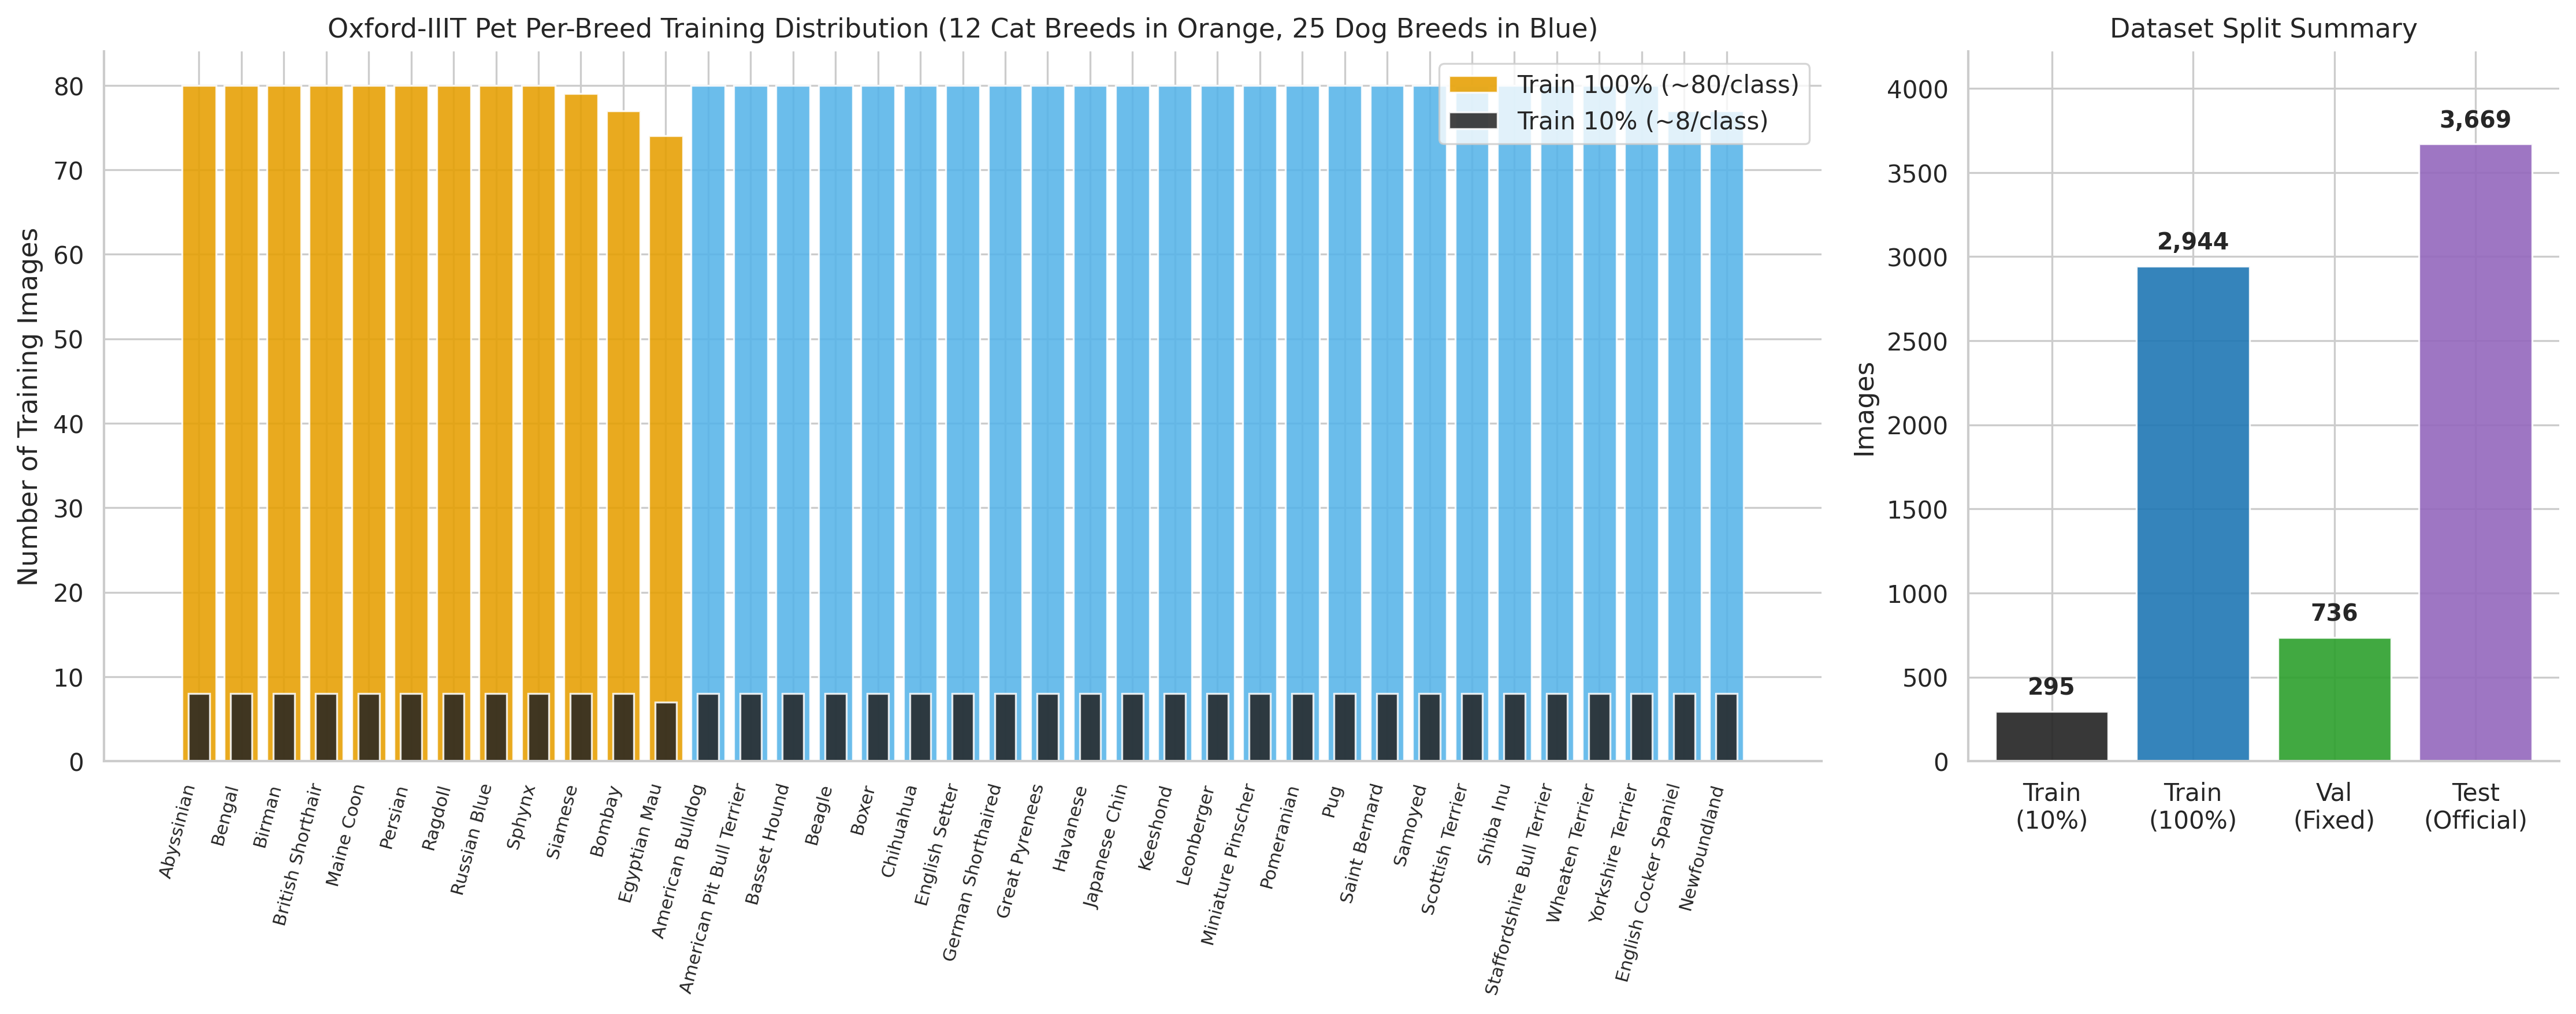

#### fig2_model_comparison_10pct.png

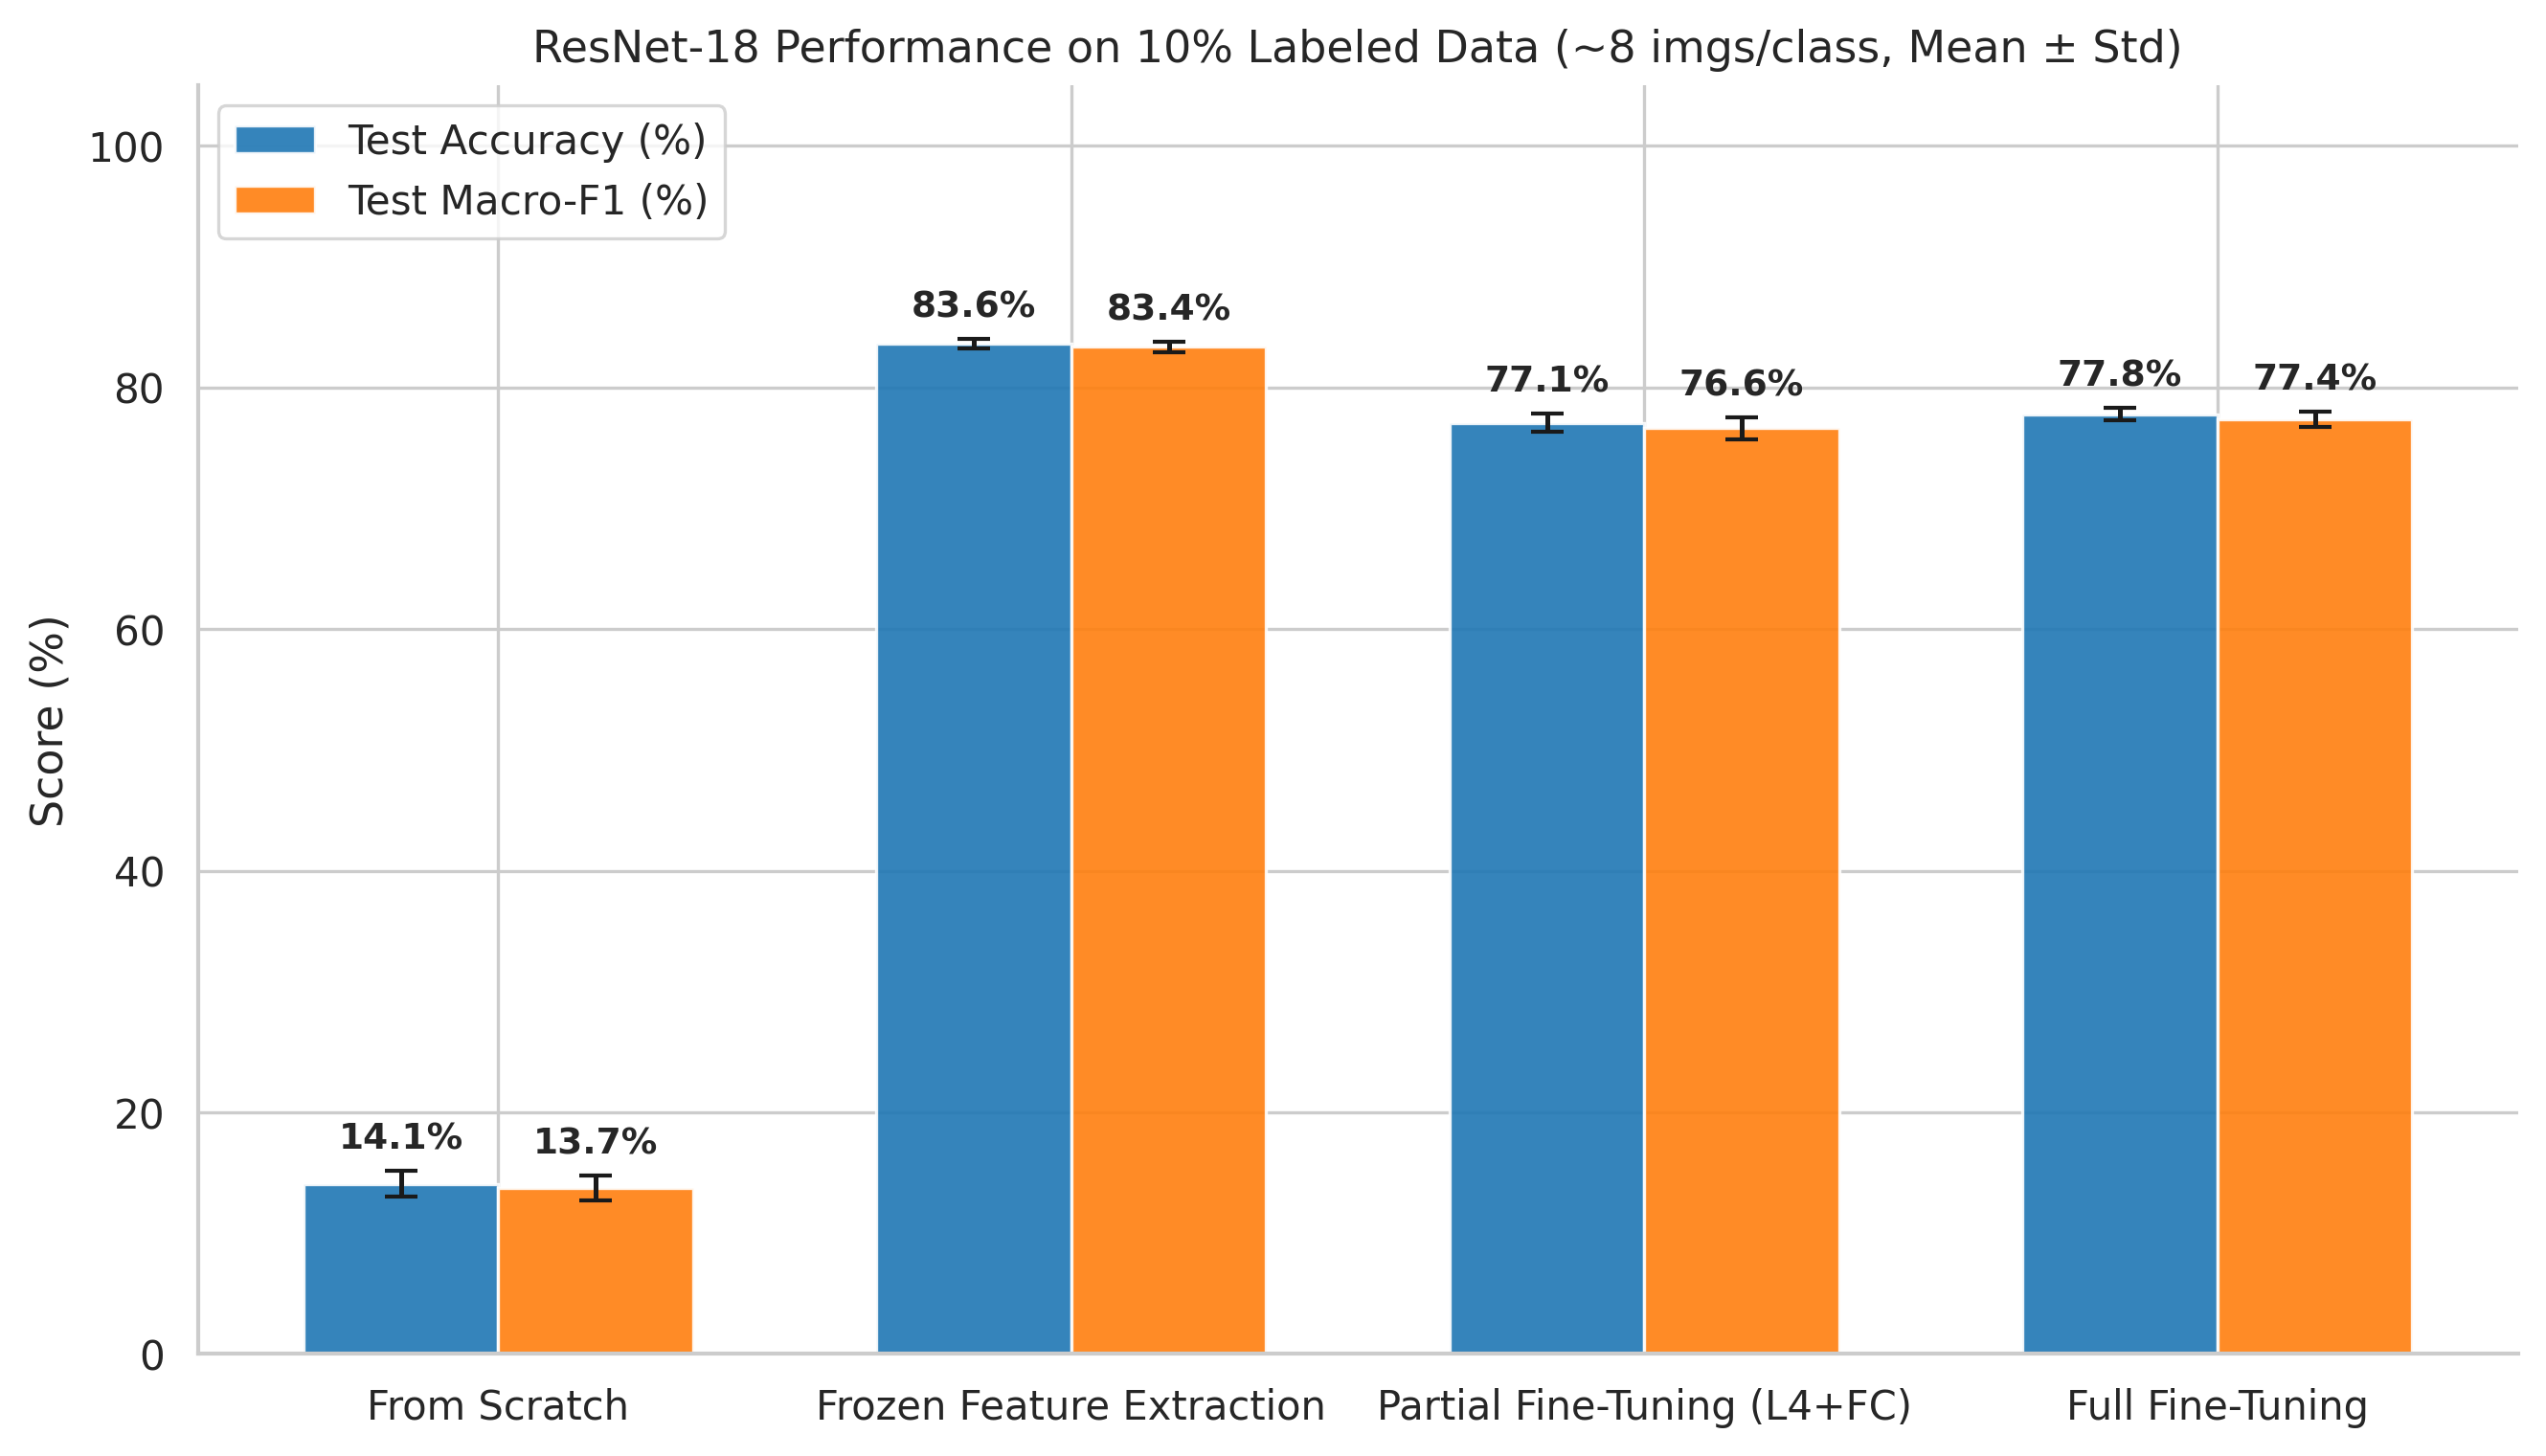

#### fig3_data_efficiency_curve.png

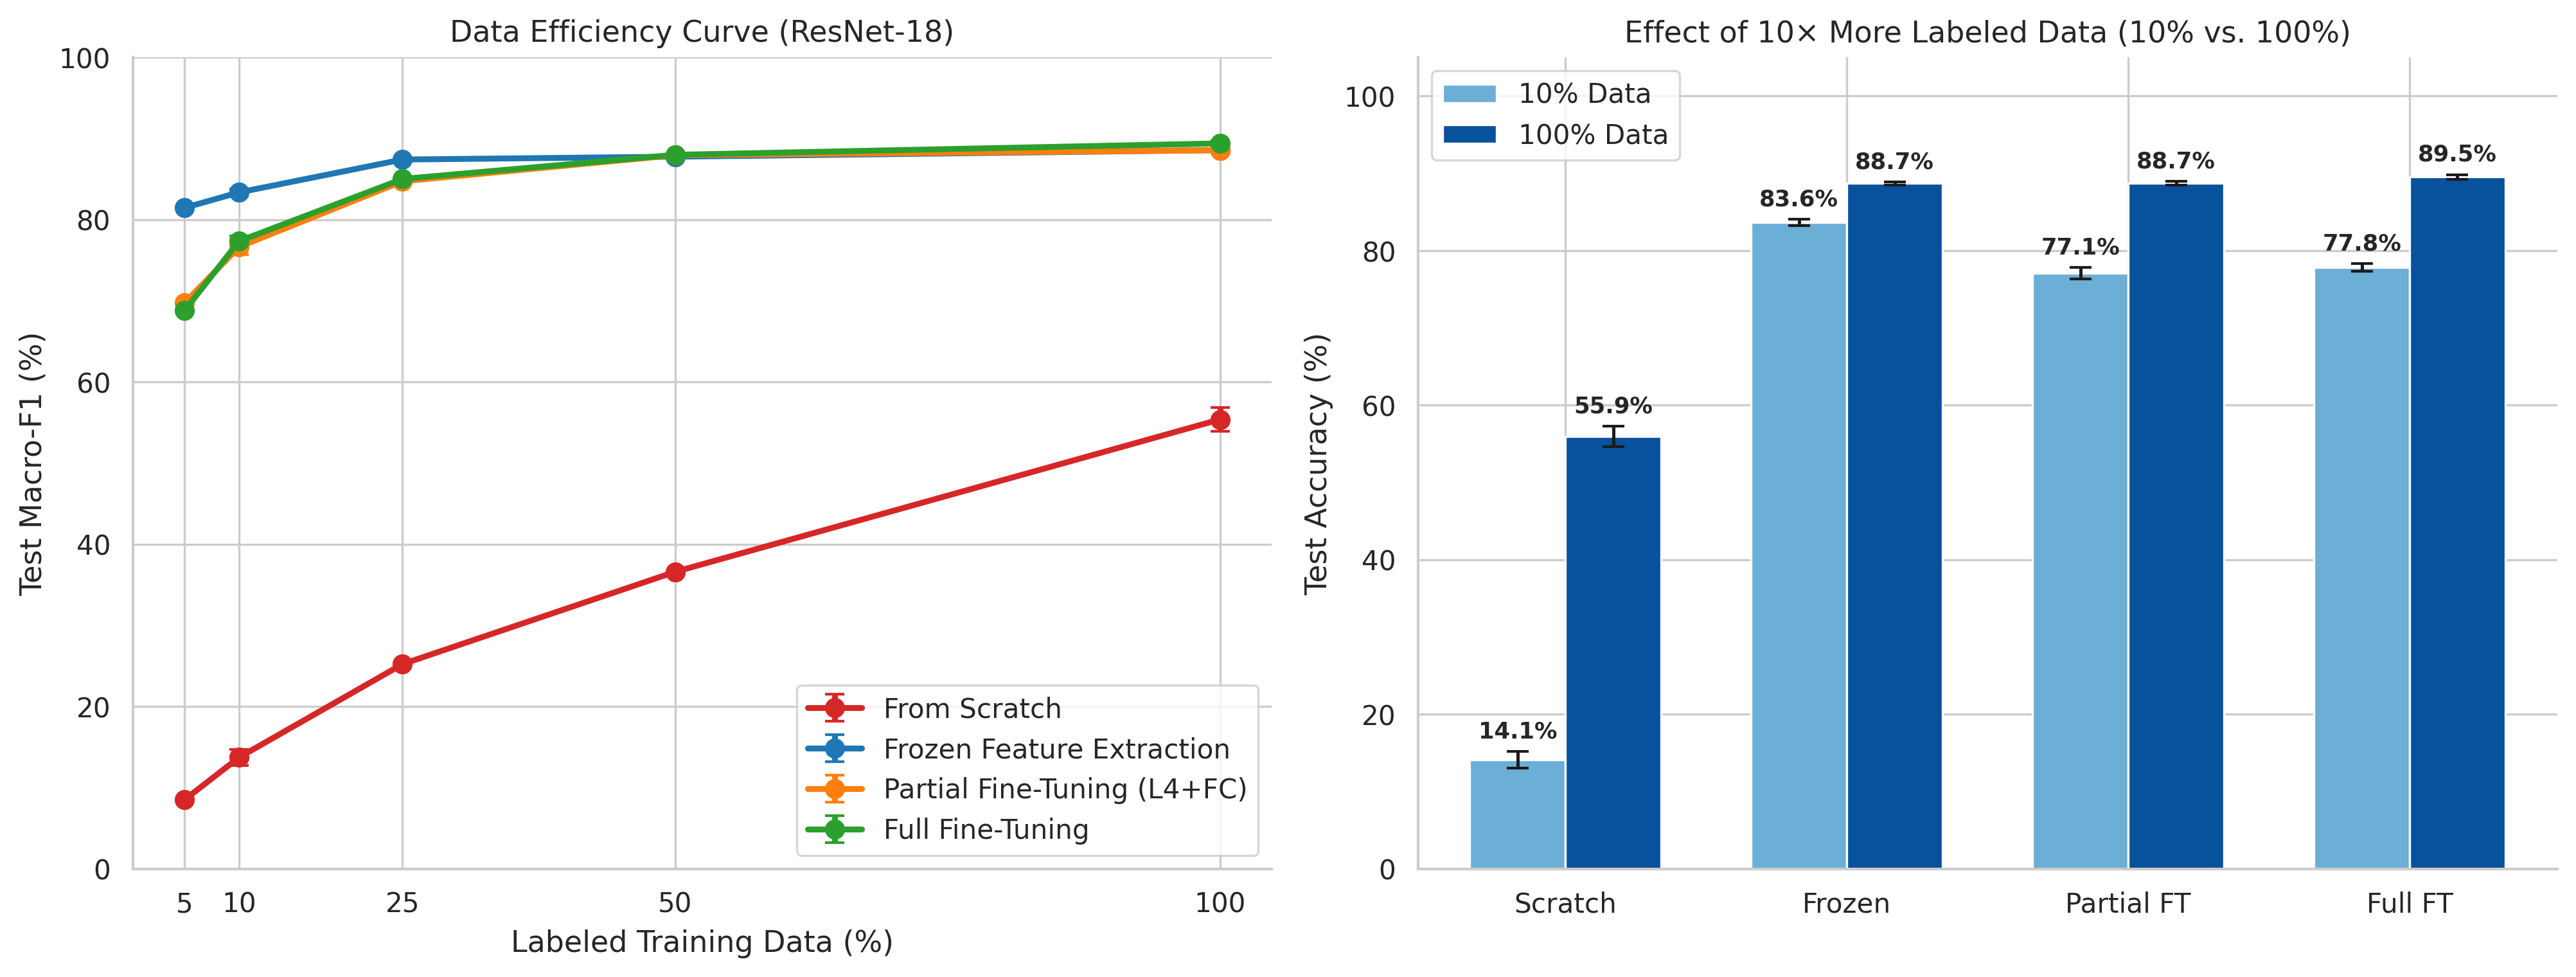

#### fig4_generalization_curves_and_gap.png

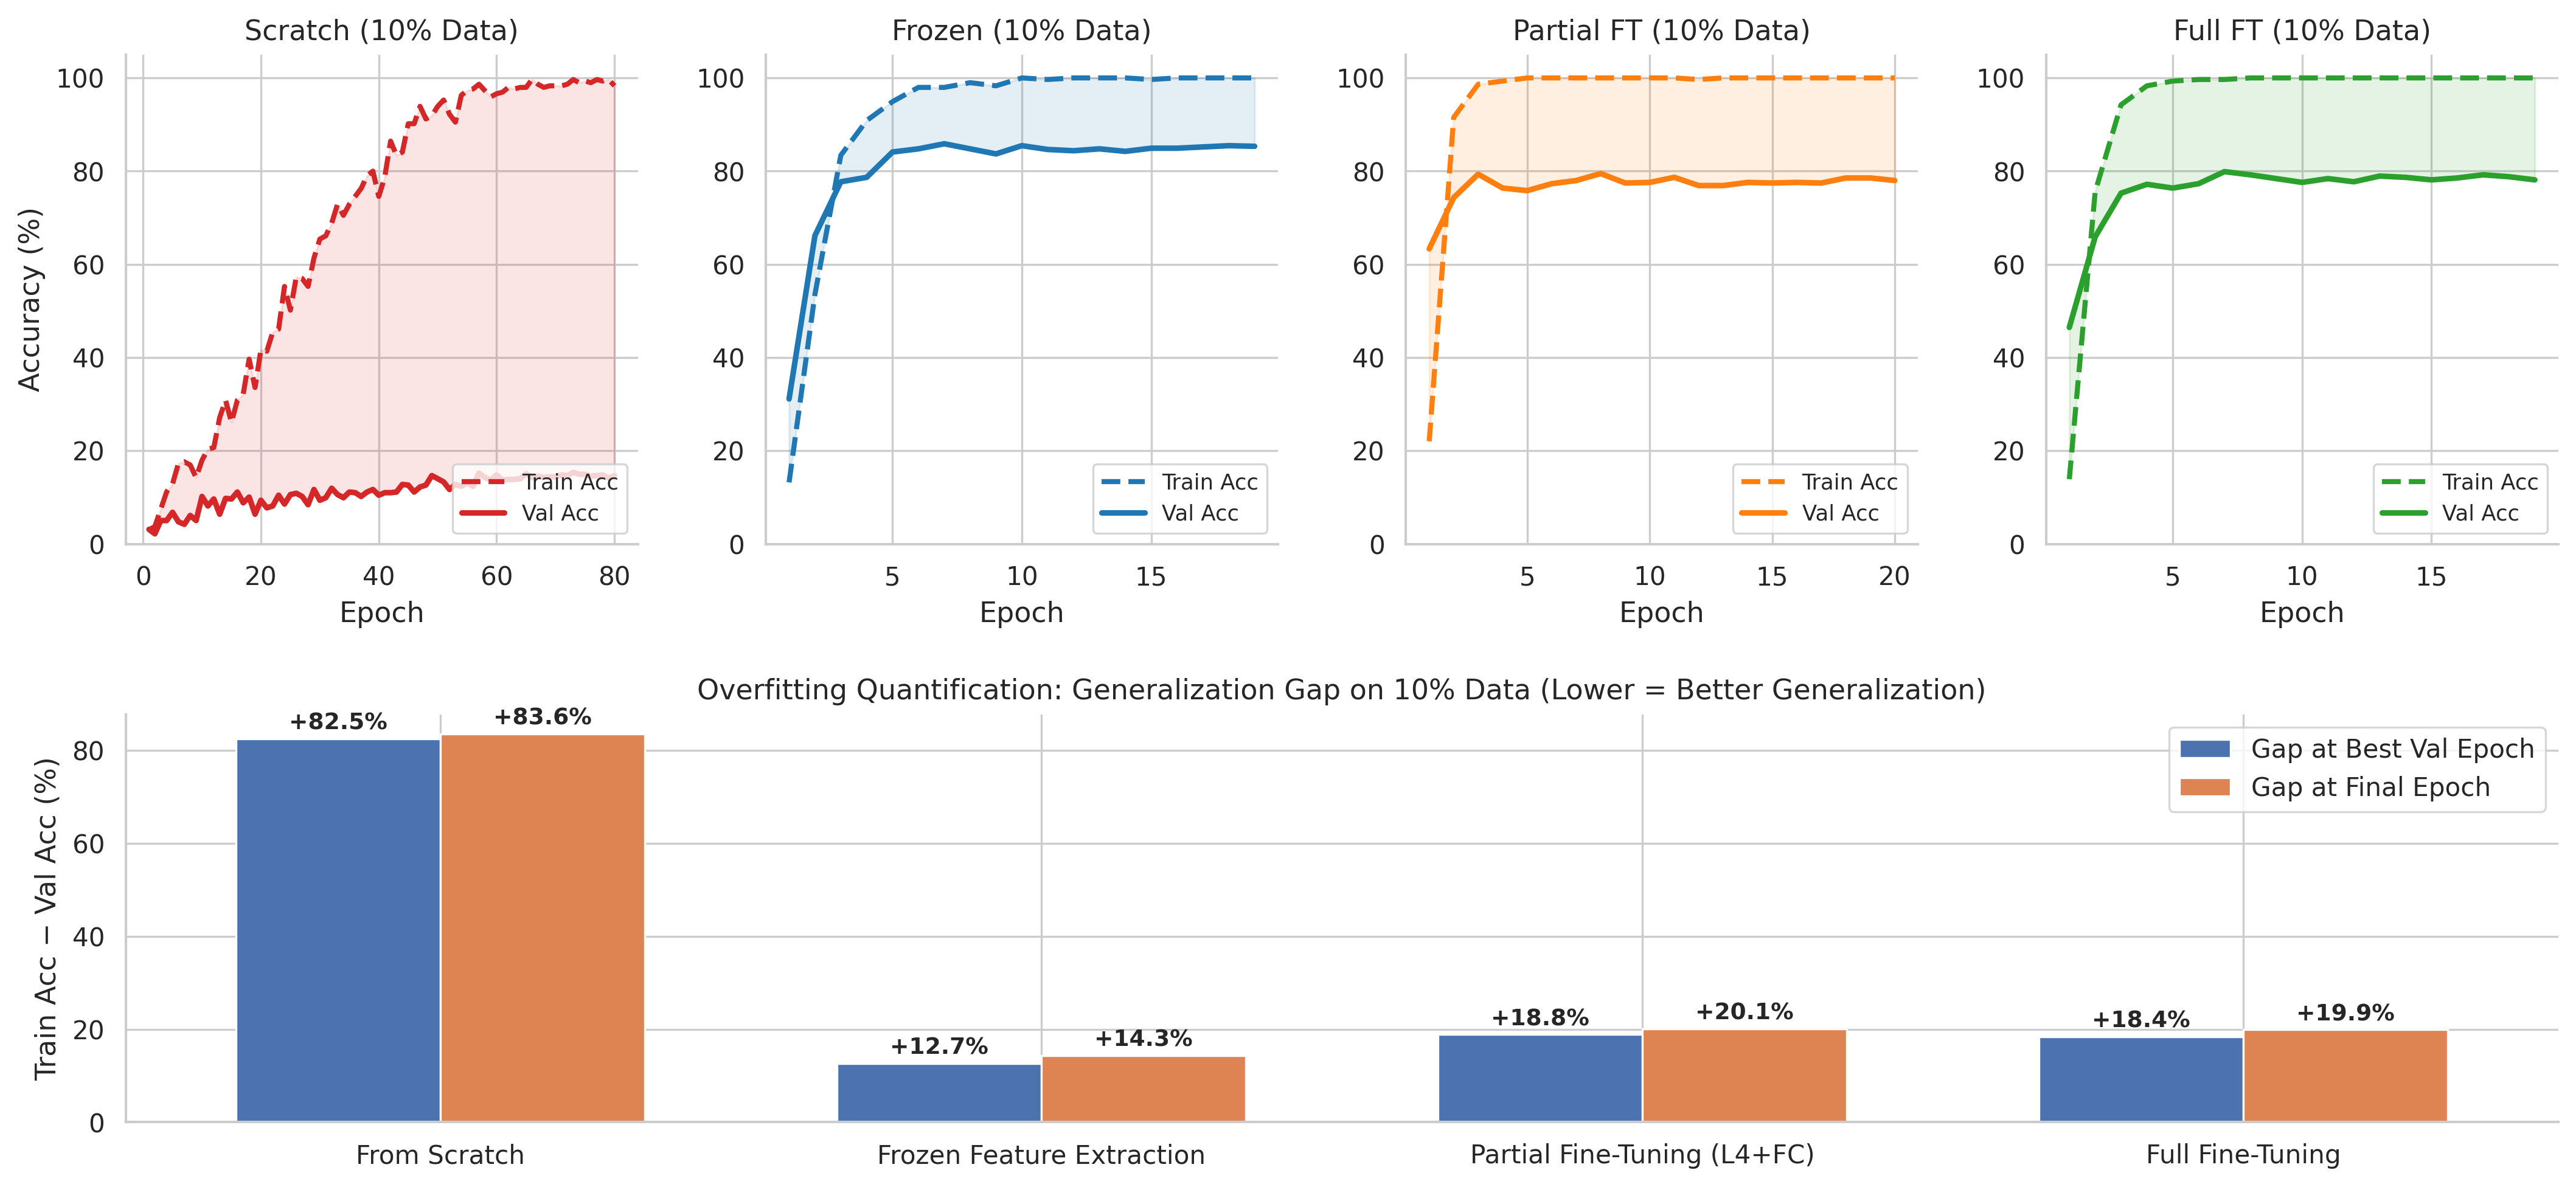

#### fig5_tsne_representations.png

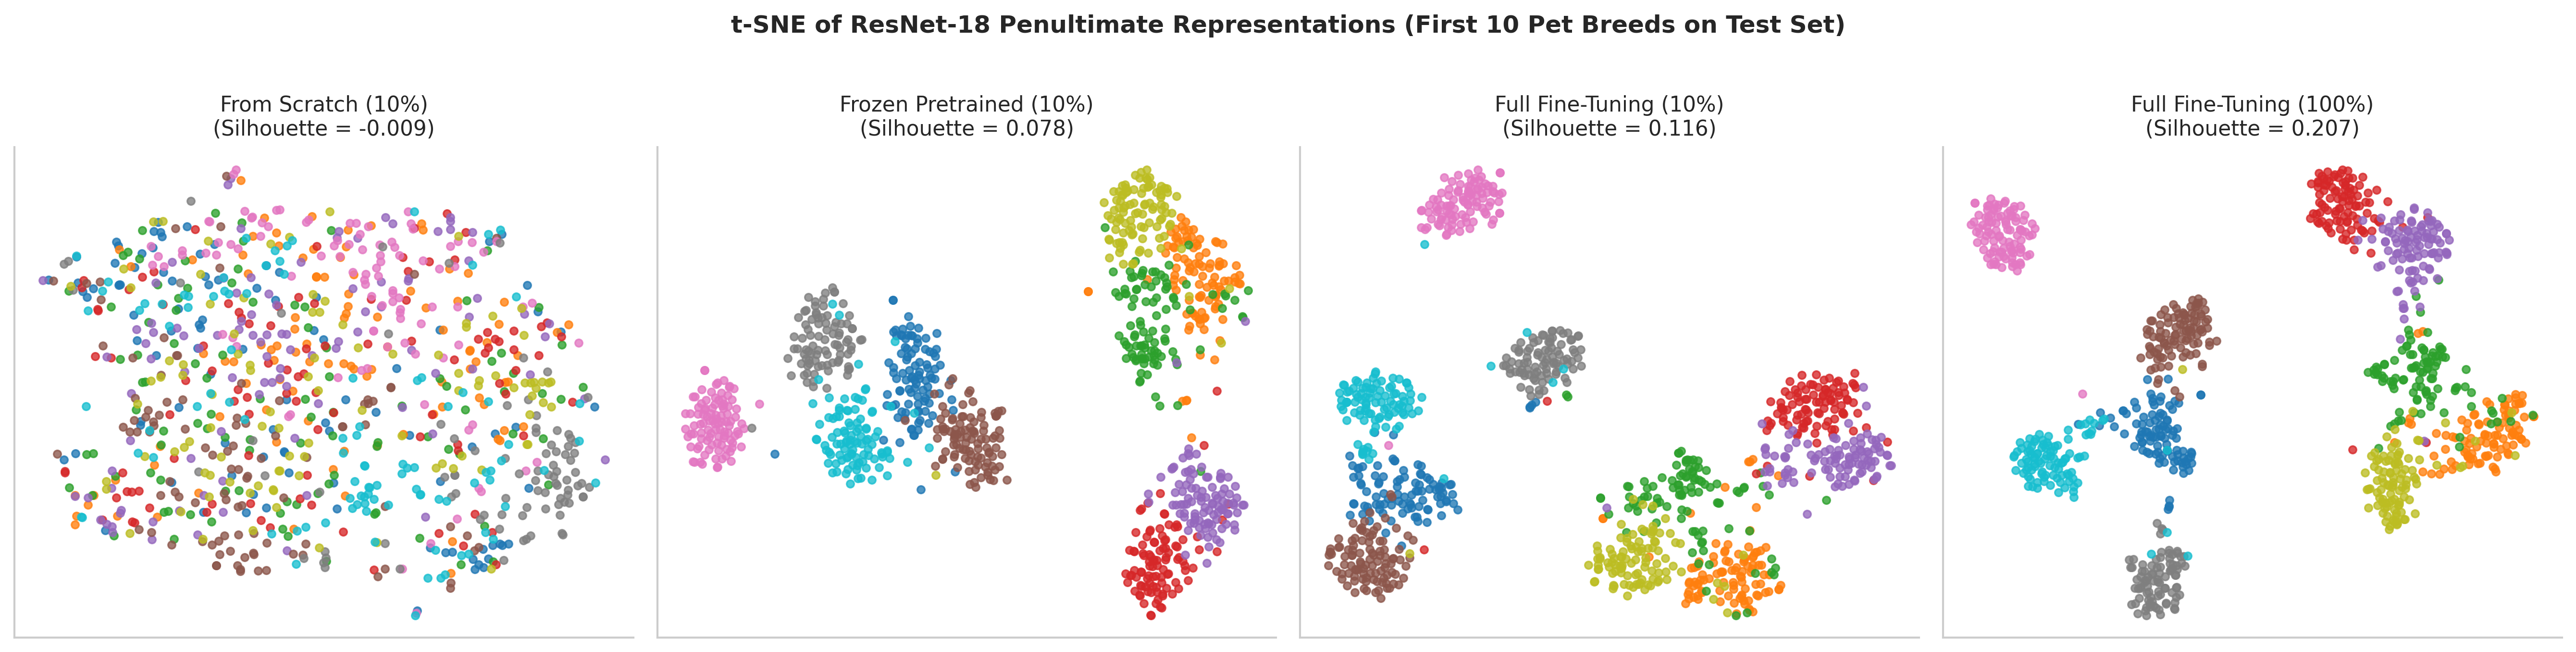

#### fig6_efficiency_tradeoff.png

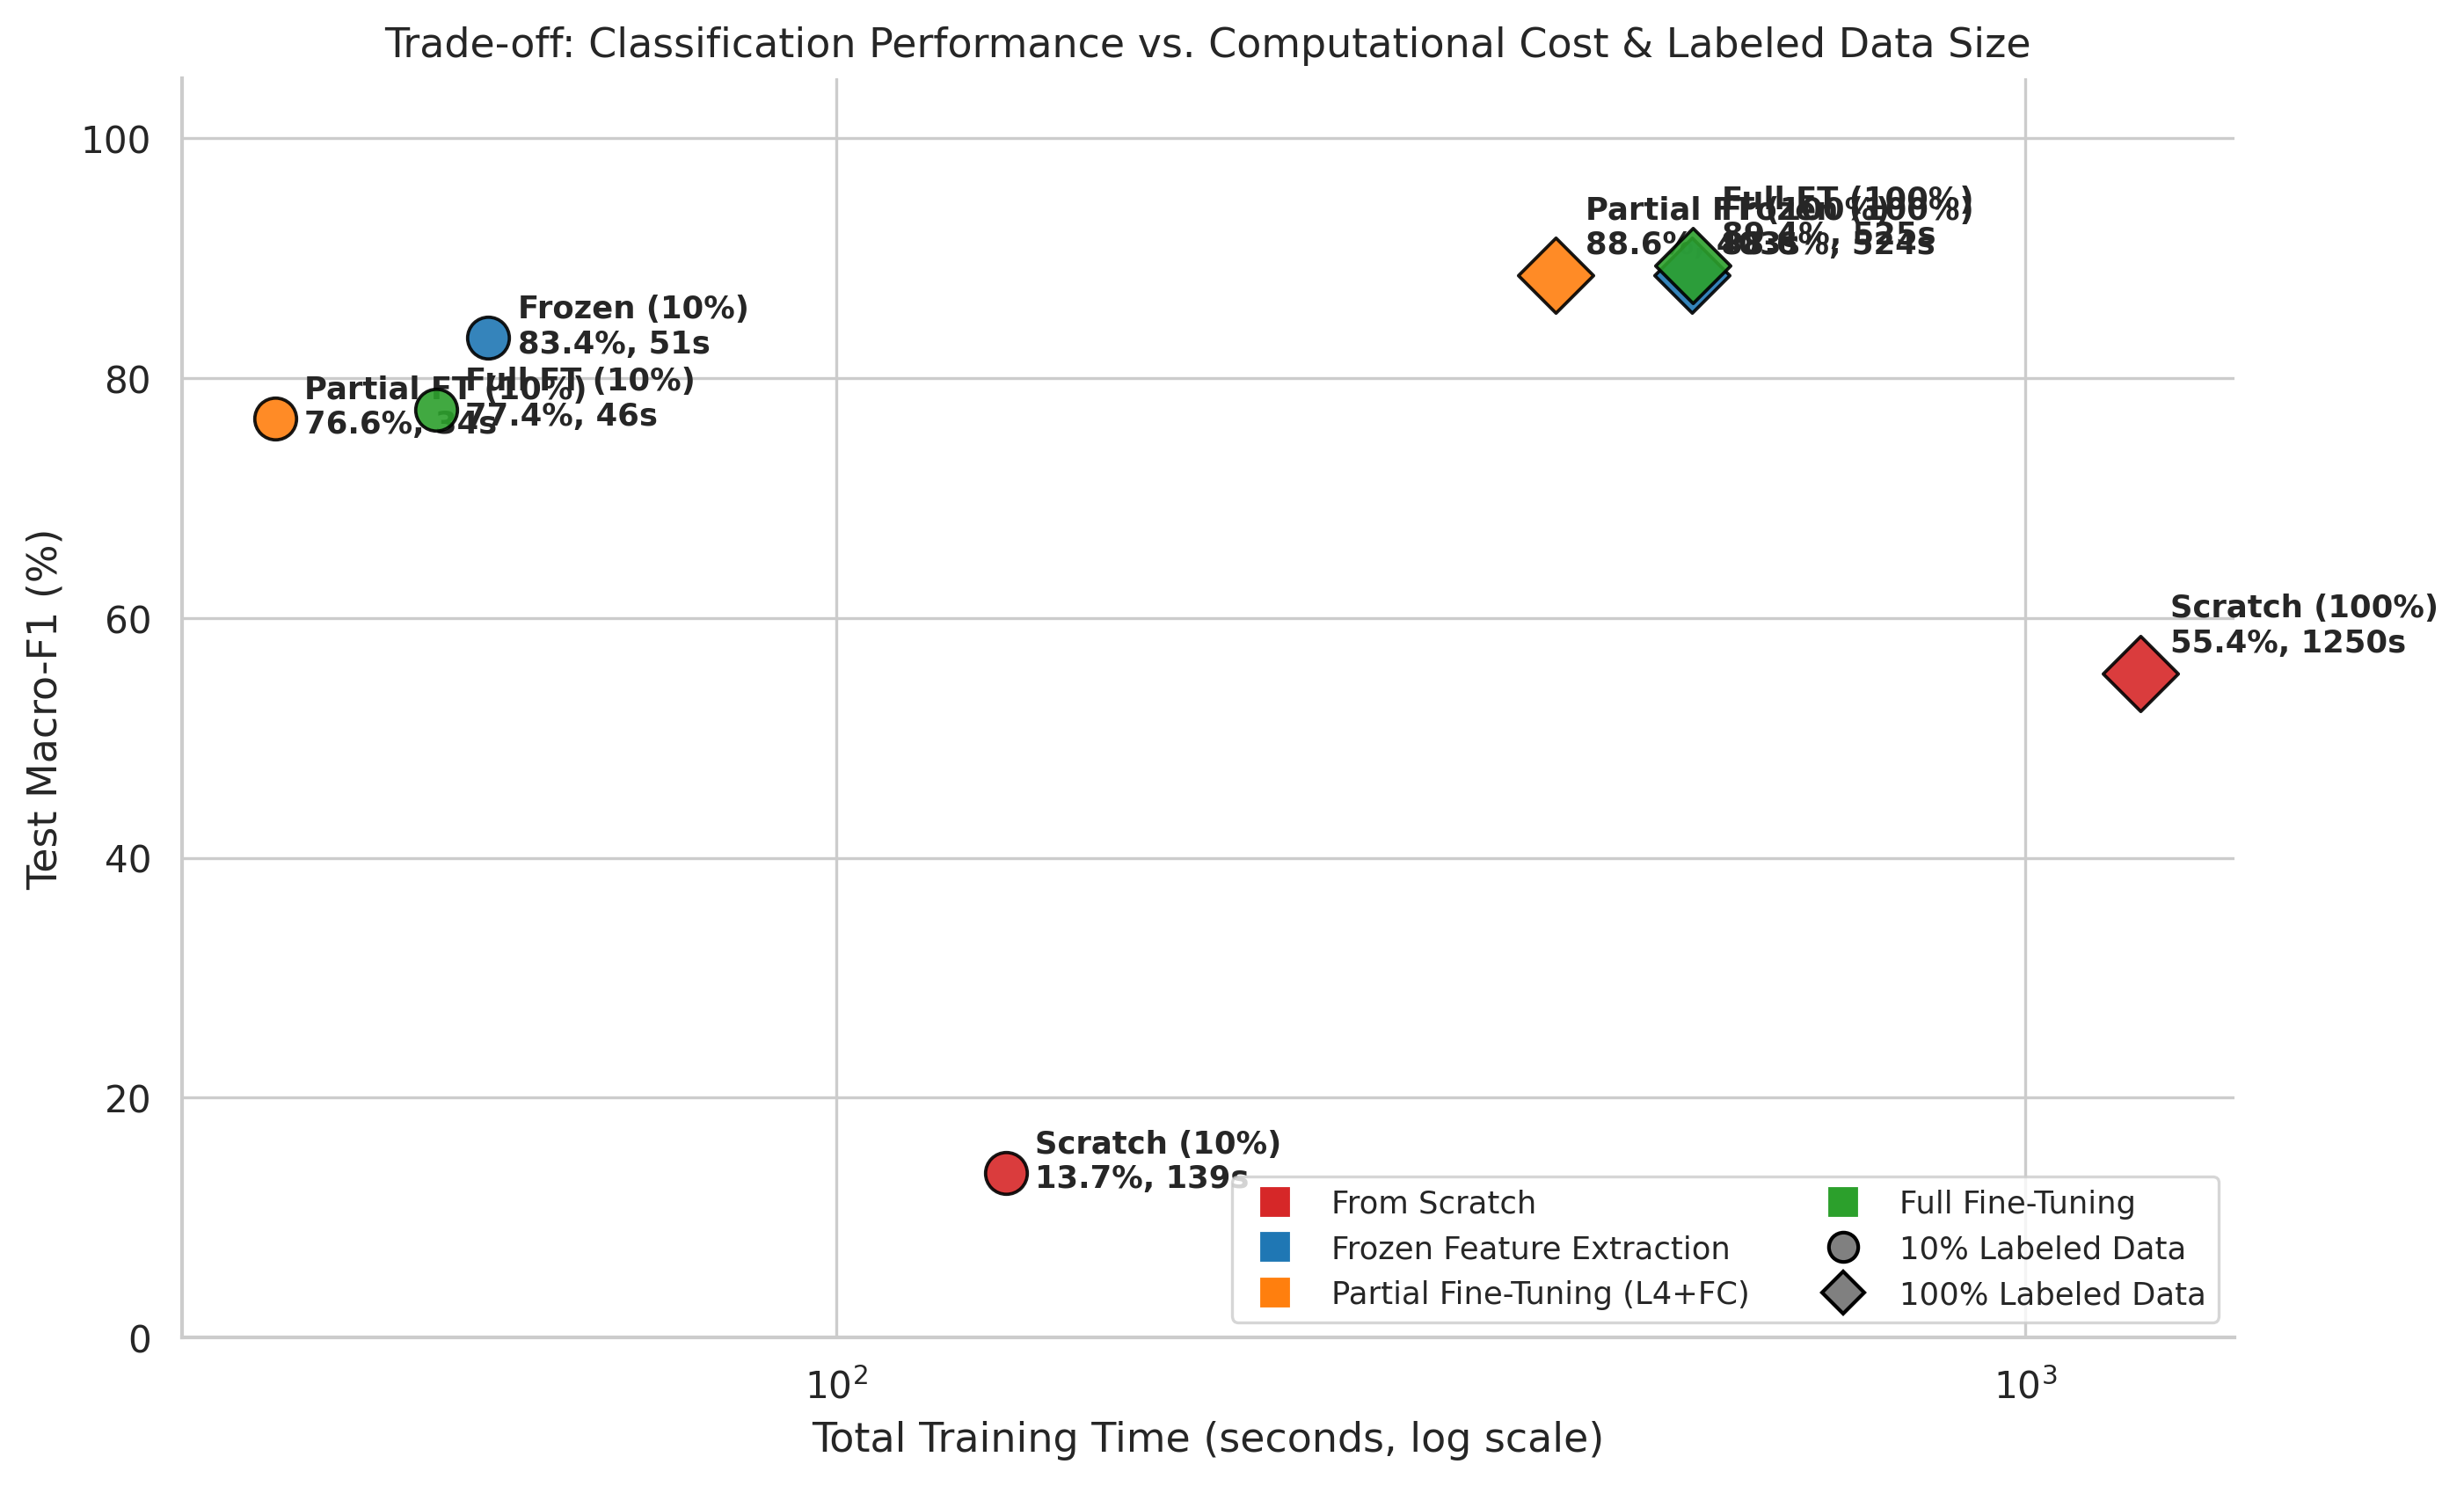

#### fig7_error_analysis.png

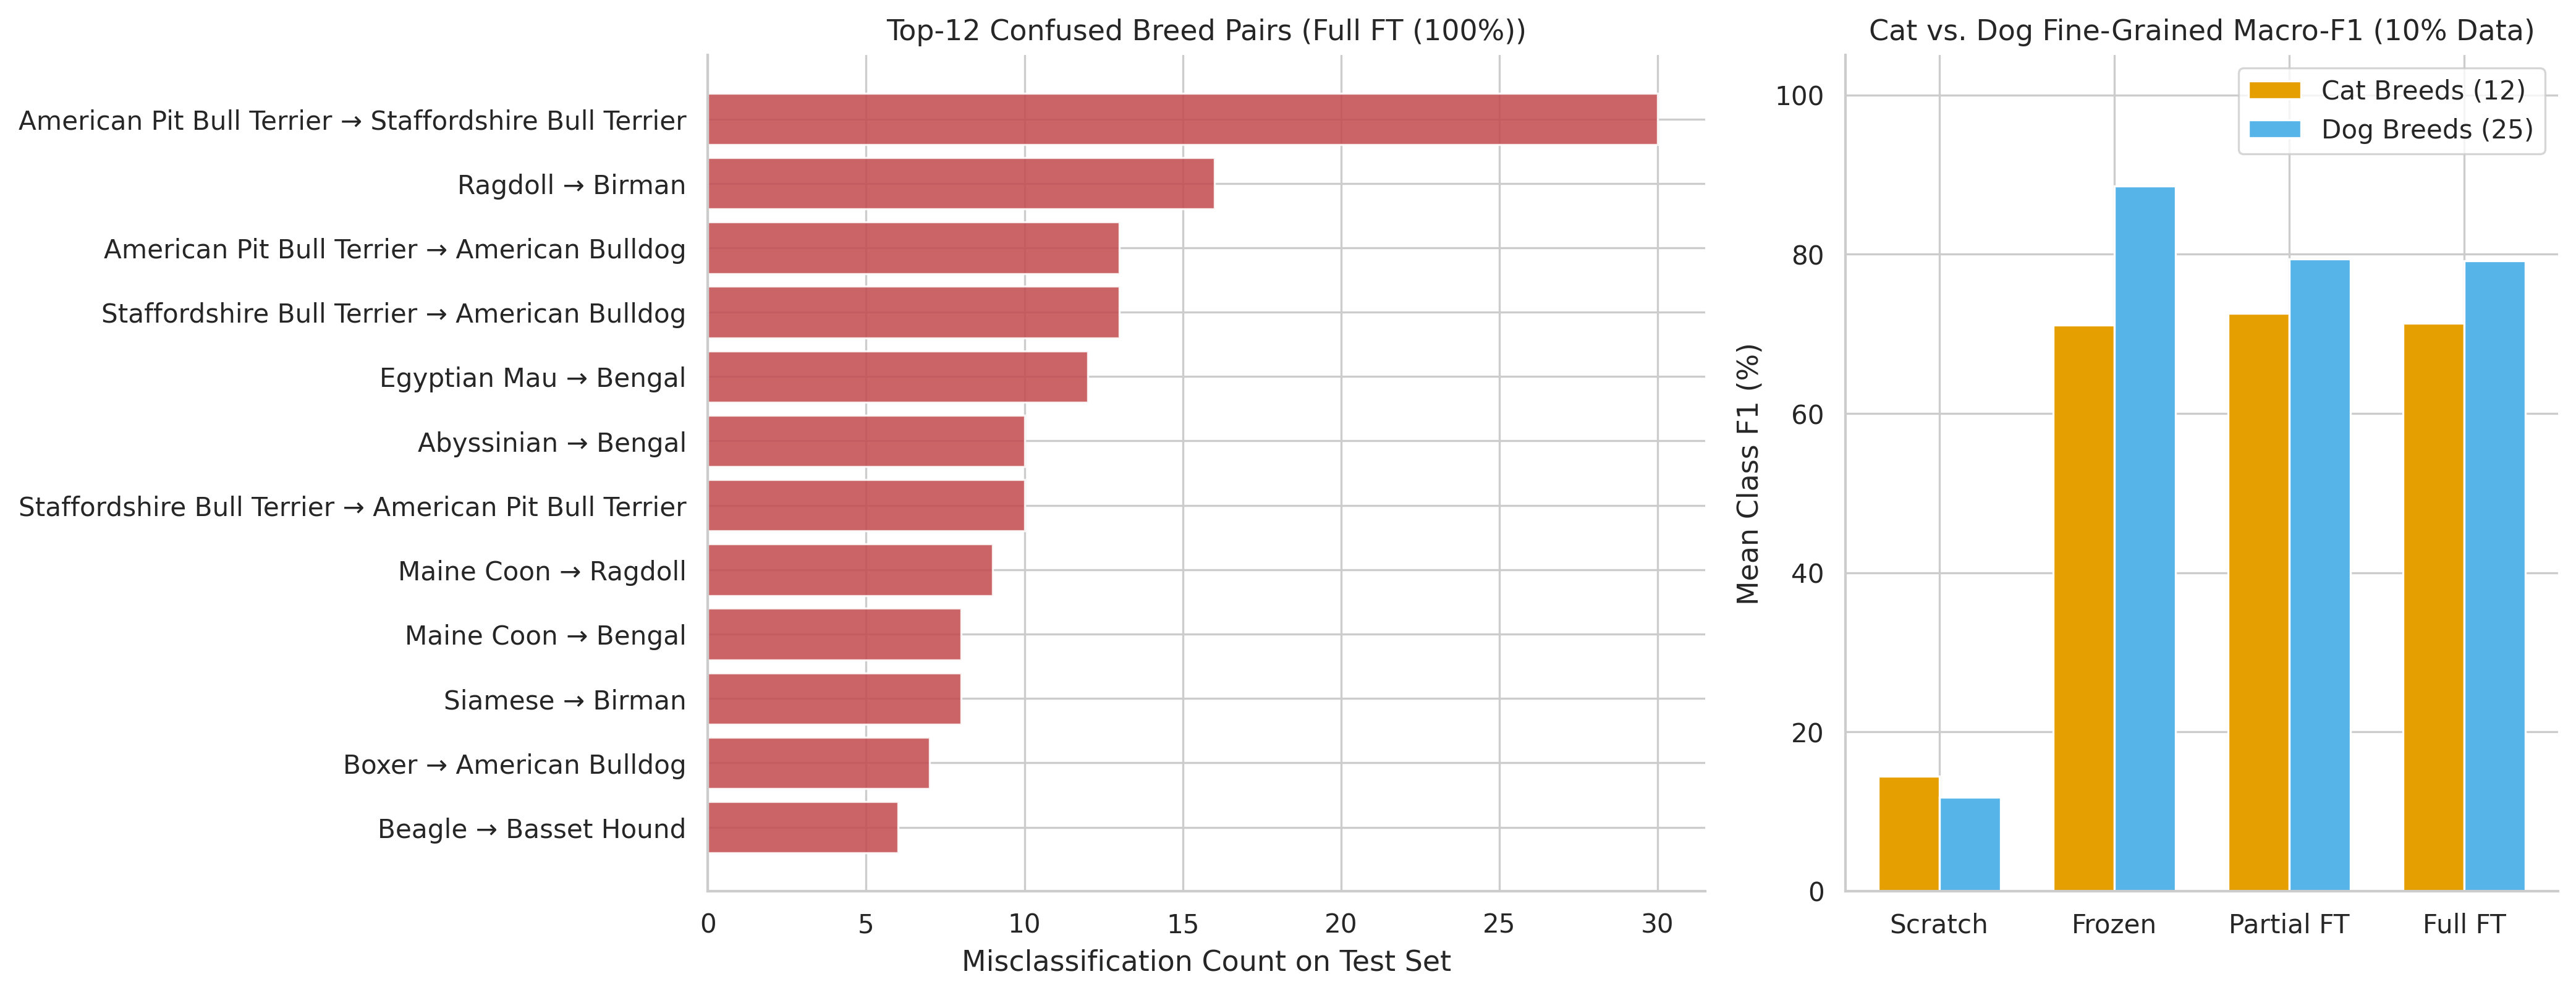

#### fig8_backbone_comparison.png

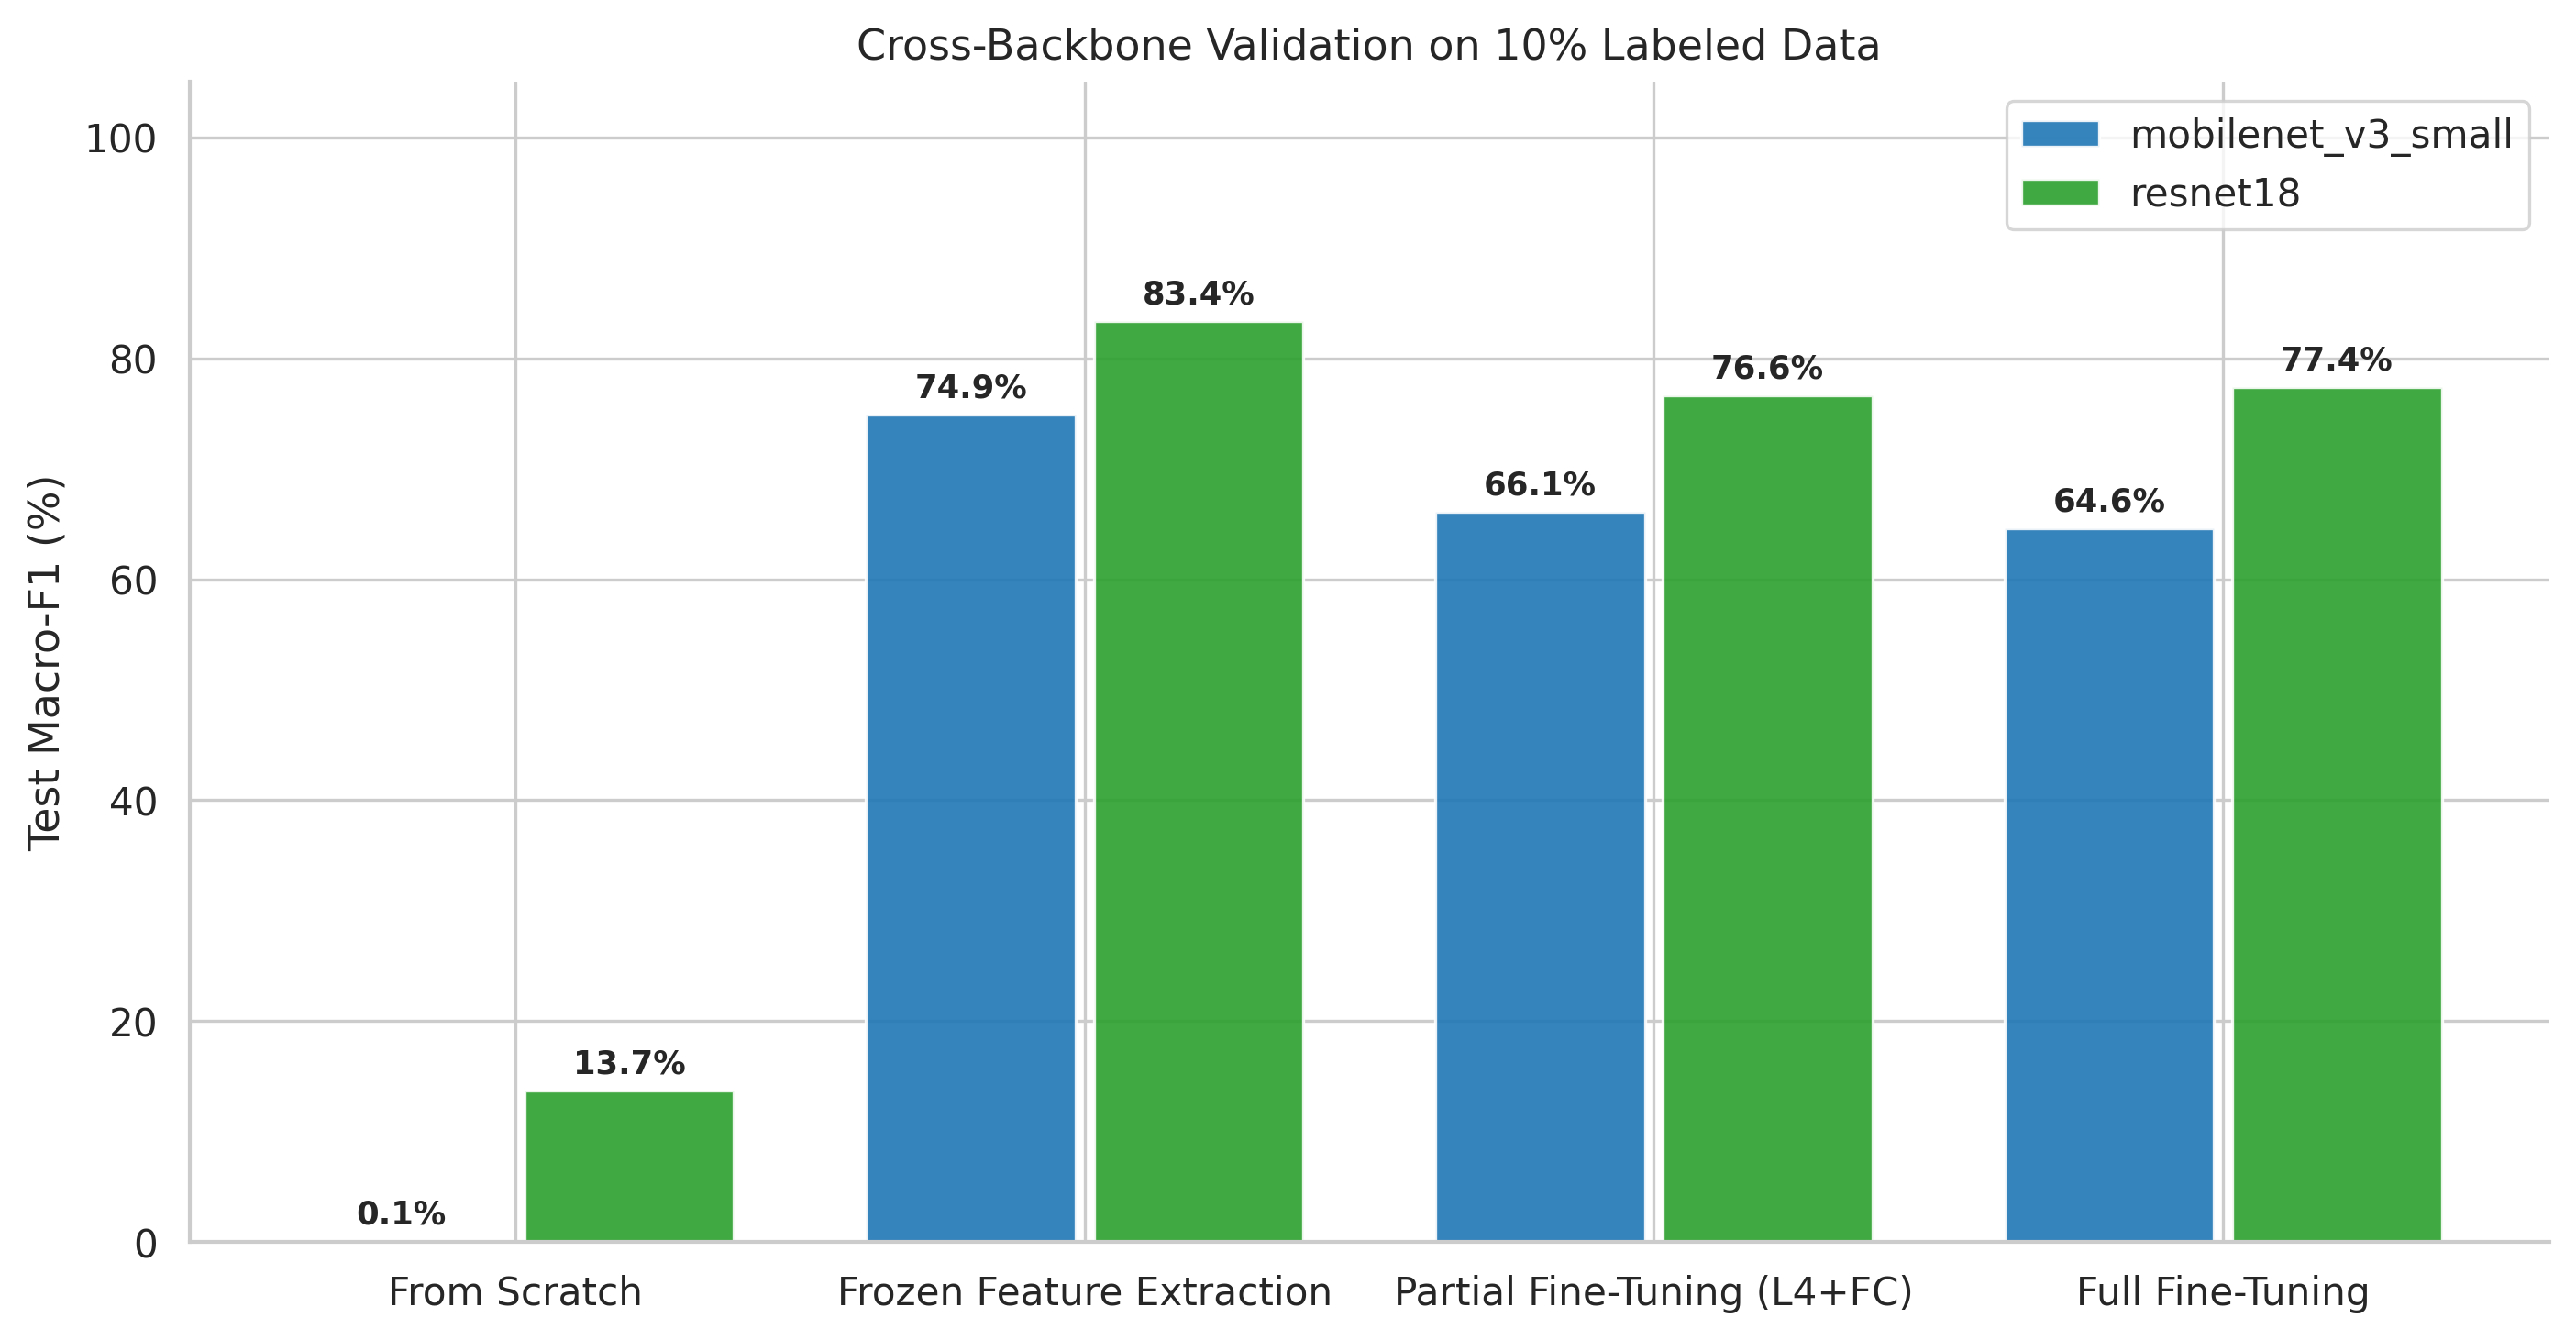

In [4]:
# 4. Display Summary Table and all Figures inline
from pathlib import Path
from IPython.display import Markdown, Image, display

RESULTS_DIR = Path("/content/dsaa5020_topic8/results")
md_path = RESULTS_DIR / "tables" / "summary_table.md"
if md_path.exists():
    display(Markdown(md_path.read_text(encoding="utf-8")))

for img_path in sorted((RESULTS_DIR / "figures").glob("*.png")):
    display(Markdown(f"#### {img_path.name}"))
    display(Image(filename=str(img_path), width=900))


In [1]:
# 5. Bundle results (tables, figures, eda_summary.json, all metrics.json) and download
import shutil
from pathlib import Path

RESULTS_DIR = Path("/content/dsaa5020_topic8/results")
zip_path = shutil.make_archive("/content/topic8_results_bundle", "zip", root_dir=RESULTS_DIR)
print("Created zip bundle:", zip_path)

try:
    from google.colab import files
    files.download(zip_path)
except Exception as e:
    print("Download skipped:", e)


FileNotFoundError: [Errno 2] No such file or directory: '/content/dsaa5020_topic8/results'